# 05 — KH03 beds: audit → monthly capacity panel

Quarterly "Beds Open Overnight" files → one capacity row per provider-month.

Reality vs the original plan: KH03 reports **sectors** (General & Acute, Learning Disability, Maternity, Mental Illness), not treatment-function specialties, and *Available* exists only by sector — so occupancy is a **provider-level** signal. Notebook 06 attaches it at provider level, repeated across that provider's specialty rows. Values are **average daily beds** over the quarter, not bed-days. All 61 files share one layout (verified: every file has the `NHS Trust by Sector` sheet with headers at row 14).

In [1]:
import pandas as pd                          # tables + excel reading (openpyxl / xlrd underneath)
import numpy as np                           # arithmetic and the zero-denominator guard
import matplotlib.pyplot as plt              # one national trend plot at the end
import os
from pathlib import Path

KH03 = Path("../data/kh03")
PROC = Path("../data/processed")
files = sorted(os.listdir(KH03))
print(len(files), "files")

61 files


## Read every file

Fixed column positions in the `NHS Trust by Sector` sheet: 1 Year, 2 Period End, 4 Org Code, 6–10 Available, 12–16 Occupied, 18–22 % Occupied (each block ordered Total, G&A, LD, Maternity, MI). A file holds exactly one quarter — asserted. An unknown Period End word would crash the `Q_START` lookup loudly, which is wanted.

In [2]:
Q_START = {"June": (0, 4), "September": (0, 7), "December": (0, 10), "March": (1, 1)}
# quarter start from 'Period End': June = Apr-Jun of the first year in '2018-19';
# March = Jan-Mar, which falls in the SECOND calendar year - hence the (offset, month) pairs

rows = []
for f in files:
    d = pd.read_excel(KH03 / f, sheet_name="NHS Trust by Sector", header=None, skiprows=15)
    d = d[d[4].notna()]                      # keeps provider rows; drops the England summary + blanks
    year, pend = d[1].mode()[0], d[2].iloc[0]
    assert (d[2] == pend).all(), f           # the period word must be uniform within a file
    assert (d[1] != year).sum() <= 1, f      # tolerates exactly one off-year row: the Q2 2013-14 file
                                             # has a '2013-15' typo on the Camden & Islington row;
                                             # a genuinely mixed file would have many off-year rows
    off, m0 = Q_START[pend]
    d = d.assign(quarter=pd.Timestamp(int(year[:4]) + off, m0, 1), file=f)
    rows.append(d[["quarter", "file", 4, 6, 7, 12, 13, 18]])

q = pd.concat(rows, ignore_index=True)
q.columns = ["quarter", "file", "provider_code", "avail_total", "avail_ga",
             "occ_total", "occ_ga", "sheet_pct_total"]
q["sheet_pct_total"] = pd.to_numeric(q["sheet_pct_total"], errors="coerce")
# the sheet prints '-' where available is 0 (2 providers in 2018-19 Q1), so that marker becomes NaN

# Q4 2014-15 is published twice (original + Revised-Nov15); the revised file
# wins, the same rule the RTT downloads use
best = q.drop_duplicates(["quarter", "file"]).sort_values("file", key=lambda s: s.str.contains("Revised"))
best = best.drop_duplicates("quarter", keep="last")[["quarter", "file"]]
q = q.merge(best, on=["quarter", "file"])

dup = q.groupby("quarter")["file"].nunique()
assert (dup == 1).all(), dup[dup > 1]        # any quarter still claimed by two files stops the notebook
print(q["quarter"].nunique(), "quarters:", q["quarter"].min().date(), "->", q["quarter"].max().date())
print(len(q), "provider-quarters")

60 quarters: 2011-04-01 -> 2026-01-01
12453 provider-quarters


## Prove the columns are the right ones

Occupancy recomputed from the raw Available/Occupied columns must equal the sheet's own `% Occupied` column — if the positions were wrong, this stops the notebook.

In [3]:
occ_total = np.where(q["avail_total"] > 0, q["occ_total"] / q["avail_total"], np.nan)
ok = q["sheet_pct_total"].notna() & (q["avail_total"] > 0)
assert np.allclose(occ_total[ok], q["sheet_pct_total"][ok], atol=1e-6)   # wrong column positions trip this

q["occupancy_total"] = occ_total
q["occupancy_ga"] = np.where(q["avail_ga"] > 0, q["occ_ga"] / q["avail_ga"], np.nan)
# avail_ga == 0 is a real case - mental-health and community trusts run no General &
# Acute beds - so occupancy there is undefined (NaN), not 0
print("provider-quarters with zero G&A beds:", int((q["avail_ga"] == 0).sum()), "of", len(q))

provider-quarters with zero G&A beds: 2117 of 12453


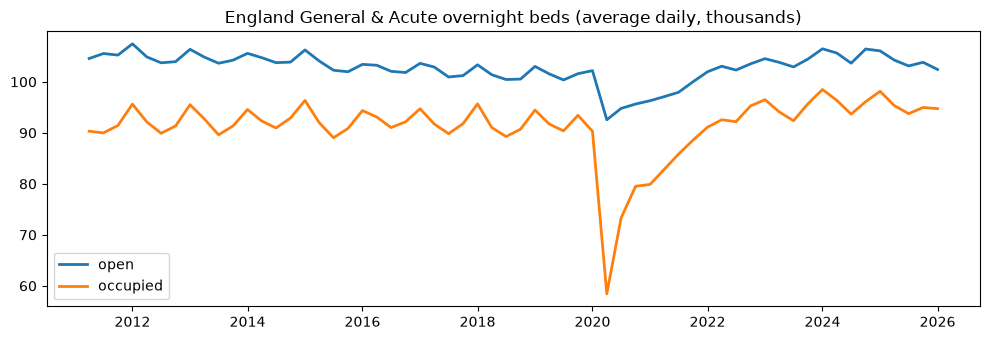

In [4]:
# national picture: average daily G&A beds open and occupied, per quarter
nat = q.groupby("quarter")[["avail_ga", "occ_ga"]].sum()

plt.figure(figsize=(10, 3.5))
plt.plot(nat.index, nat["avail_ga"] / 1000, linewidth=2, label="open")
plt.plot(nat.index, nat["occ_ga"] / 1000, linewidth=2, label="occupied")
plt.title("England General & Acute overnight beds (average daily, thousands)")
plt.legend()
plt.tight_layout()
plt.show()

## Quarterly → monthly, save

Average daily beds are a level, so each of the quarter's 3 months inherits the quarter's value.

In [5]:
m = q.loc[q.index.repeat(3)].reset_index(drop=True)          # three copies of every quarter row
m["month"] = (m["quarter"].dt.to_period("M") + np.tile([0, 1, 2], len(q))).dt.to_timestamp()

out = m[["month", "provider_code", "avail_ga", "occ_ga", "occupancy_ga",
         "avail_total", "occ_total", "occupancy_total"]]
assert not out.duplicated(["provider_code", "month"]).any()   # one capacity row per provider-month
out.to_csv(PROC / "kh03_monthly_panel.csv", index=False)
print(out.shape, "->", PROC / "kh03_monthly_panel.csv")

(37359, 8) -> ..\data\processed\kh03_monthly_panel.csv
